In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

import models.densenet as models

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

from utils import get_device, heatmap, project

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from dataset.utils import *

device = get_device(cpu=True)

concept_index_to_string = IndexToString("../dataset/chexpert/splits/cbm/concepts.txt")

N_CONCEPT = 13

#XtoC = models.vgg16_bn(pretrained=True, num_classes=N_CONCEPT)
XtoC = models.densenet121(pretrained=False, num_classes=N_CONCEPT)
#XtoC.load_state_dict(torch.load("./../saves/chexpert_XtoC_converted.pth"))
XtoC.load_state_dict(torch.load("./../saves/densenet121_chexpert.pth"), strict=False)
XtoC.to(device)
XtoC.eval()

print("model loaded")

Device: cpu NVIDIA GeForce RTX 3050 Ti Laptop GPU
model loaded


In [3]:
XtoC = convert(XtoC).to(device)

print(XtoC)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): _DenseBlock(
    (denselayer1): _DenseLayer(
      (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu1): ReLU(inplace=True)
      (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu2): ReLU(inplace=True)
      (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    )
    (denselayer2): _DenseLayer(
      (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu1): ReLU(inplace=True)
      (conv1): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=

In [4]:
def plot(imgs, orig_img, with_orig=True, row_title=None, **imshow_kwargs):
	if not isinstance(imgs[0], list):
		# Make a 2d grid even if there's just 1 row
		imgs = [imgs]


	num_rows = len(imgs)
	num_cols = len(imgs[0]) + with_orig
	fig, axs = plt.subplots(nrows=num_rows, ncols=num_cols, squeeze=False)
	for row_idx, row in enumerate(imgs):
		row = [orig_img] + row if with_orig else row
		for col_idx, img in enumerate(row):
			if isinstance(img, torch.Tensor):
				img = img.permute(1, 2, 0)
			ax = axs[row_idx, col_idx]
			ax.imshow(np.asarray(img), **imshow_kwargs)
			ax.set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

	if with_orig:
		axs[0, 0].set(title='Original image')
		axs[0, 0].title.set_size(8)
	if row_title is not None:
		for row_idx in range(num_rows):
			axs[row_idx, 0].set(ylabel=row_title[row_idx])

	plt.tight_layout()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


True image size (channels, width, height): torch.Size([3, 320, 328])
True  image concepts: tensor([0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 0., 0., 1.])


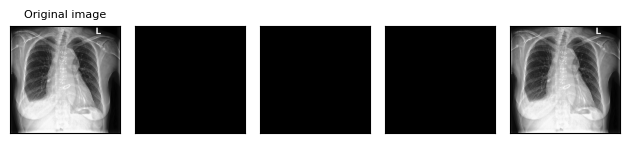

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


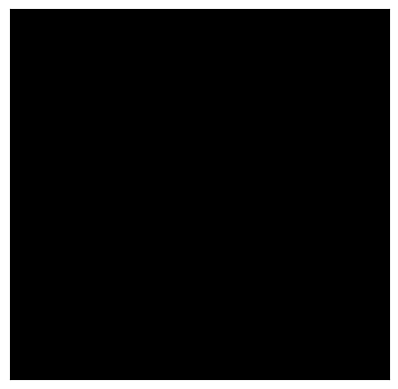

In [25]:
from PIL import Image
import torchvision.transforms.functional as TF

is_training = True

if is_training:
	transform = transforms.Compose([
		transforms.Resize(320),
		#transforms.CenterCrop(320),
		#transforms.RandomResizedCrop(320),
		transforms.RandomHorizontalFlip(),
		transforms.ColorJitter(brightness=0.1),
		transforms.RandomAffine(degrees=(-15, 15), translate=(0.05, 0.05), scale=(0.95, 1.05), fill=128),
		transforms.ToTensor(), #implicitly divides by 255
		#transforms.Normalize(mean = [0.5, 0.5, 0.5], std = [2, 2, 2])
	])
else:
	transform = transforms.Compose([
		transforms.Resize(320 + 25),
		transforms.CenterCrop(320),
		transforms.ToTensor(), #implicitly divides by 255
		transforms.Normalize(mean = [0.5, 0.5, 0.5], std = [2, 2, 2])
	])

samples = [
	("./../dataset/chexpert/train/patient19472/study1/view1_frontal.jpg", [0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]),
	("./../dataset/chexpert/train/patient33904/study2/view2_lateral.jpg", [0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0]),
	("./../dataset/chexpert/train/patient36757/study2/view1_frontal.jpg", [0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1]),
	("./../dataset/chexpert/train/patient07832/study2/view1_frontal.jpg", [0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]),
	("./../dataset/chexpert/train/patient55904/study2/view1_frontal.jpg", [0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1]),
	("./../dataset/chexpert/train/patient26669/study1/view1_frontal.jpg", [0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1]),
	("./../dataset/chexpert/train/patient13835/study2/view1_frontal.jpg", [0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1]),
	("./../dataset/chexpert/train/patient39872/study3/view1_frontal.jpg", [0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1]),
	("./../dataset/chexpert/train/patient24393/study6/view1_frontal.jpg", [0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1]),
	("./../dataset/chexpert/train/patient41967/study1/view1_frontal.jpg", [0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1]),
	("./../dataset/chexpert/train/patient35770/study3/view1_frontal.jpg", [0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1]),
	("./../dataset/chexpert/train/patient29307/study4/view3_lateral.jpg", [0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0]),
	("./../dataset/chexpert/train/patient31061/study3/view2_lateral.jpg", [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0]),
	("./../dataset/chexpert/train/patient10037/study4/view1_frontal.jpg", [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0]),
	("./../dataset/chexpert/train/patient53824/study1/view1_frontal.jpg", [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1]),
	("./../dataset/chexpert/train/patient10174/study8/view1_frontal.jpg", [0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0]),
	("./../dataset/chexpert/train/patient60480/study1/view2_frontal.jpg", [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0]),
	("./../dataset/chexpert/train/patient12009/study1/view1_frontal.jpg", [0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0]),
	("./../dataset/chexpert/train/patient32595/study19/view1_frontal.jpg", [0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0]),
	("./../dataset/chexpert/train/patient35601/study2/view1_frontal.jpg", [0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0]),
	("./../dataset/chexpert/train/patient15415/study10/view1_frontal.jpg", [0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1]),
	("./../dataset/chexpert/train/patient42880/study10/view1_frontal.jpg", [0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1]),
	("./../dataset/chexpert/train/patient40945/study5/view1_frontal.jpg", [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1])
]

sample_index = 5

orig_image = Image.open(samples[sample_index][0]).convert('RGB')

sample_images = [transform(orig_image) for i in range(4)]
plot(sample_images, orig_image)

image, concepts = transform(orig_image).to(device), torch.FloatTensor(samples[sample_index][1]).to(device)

# print / show input
print("True image size (channels, width, height):", image.size())
print("True  image concepts:", concepts)

plt.xticks([])
plt.yticks([])
plt.imshow(TF.to_tensor(orig_image).permute(1, 2, 0))
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(image.permute(1, 2, 0))
plt.show()

In [6]:
image, concepts = transform(orig_image).to(device), torch.FloatTensor(samples[0][1]).to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None

# get model prediction and LRP map for classification
prediction = XtoC(image)

print(prediction)

pred_concepts_readable = torch.nn.Sigmoid()(prediction)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

RuntimeError: mat1 and mat2 shapes cannot be multiplied (10240x10 and 1024x13)

In [11]:
XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
    if idx < 24:
        XtoC_model_1.append(m)
    elif idx < 46:
        XtoC_model_2.append(m)
    else:
        XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

XtoC_model_1.to(device).eval()
XtoC_model_2.to(device).eval()
XtoC_model_3.to(device).eval()

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (9): ReLU()
  (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (12): ReLU()
  (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (14): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): BatchNorm2d(256, eps=1e-05, momentum

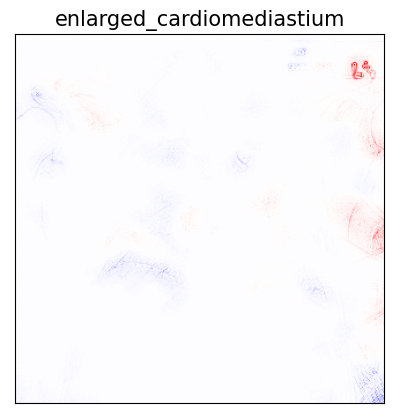

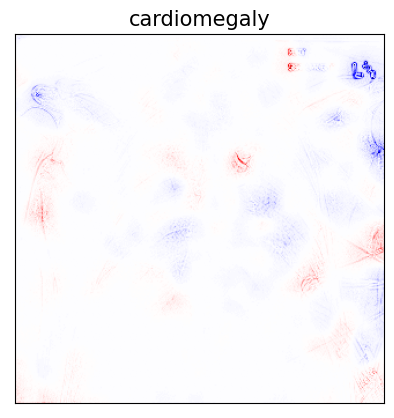

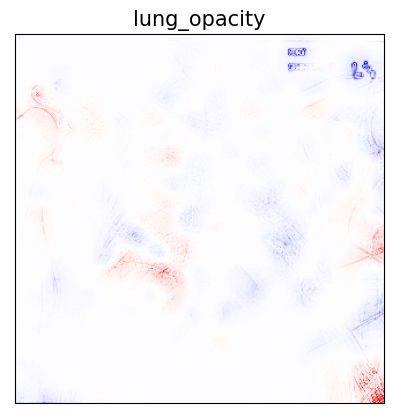

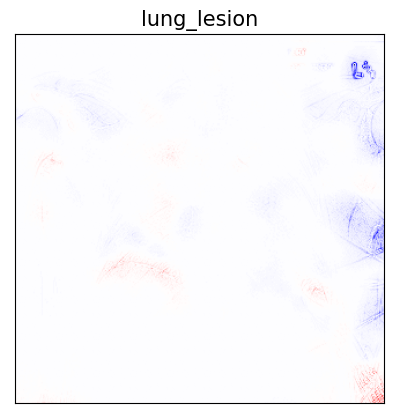

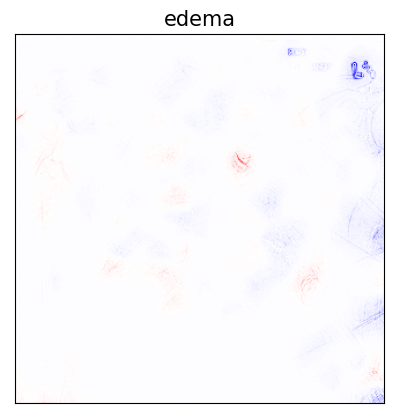

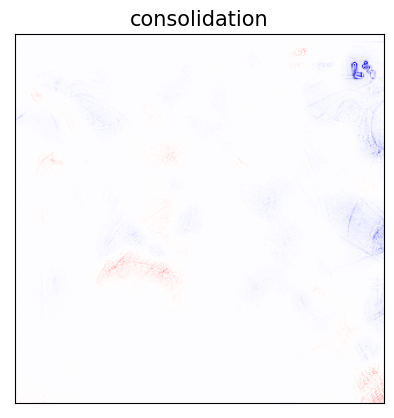

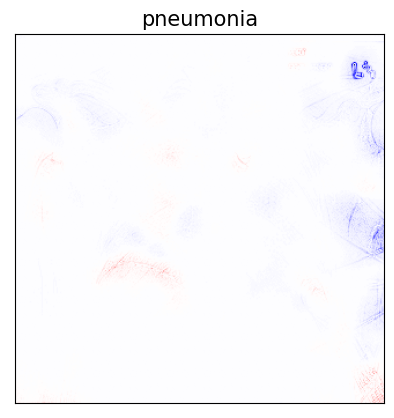

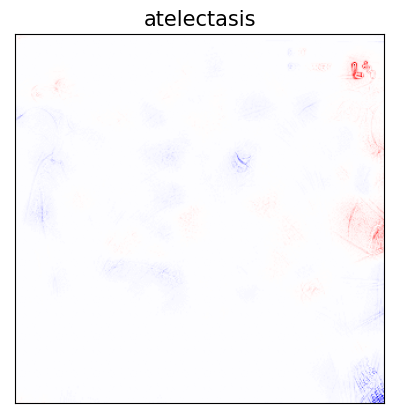

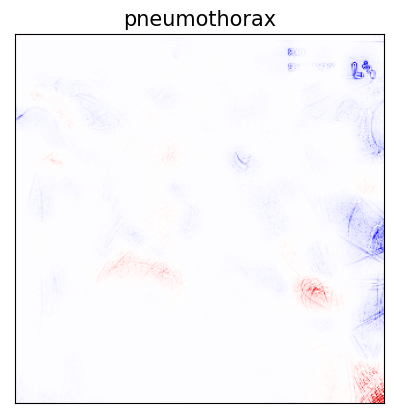

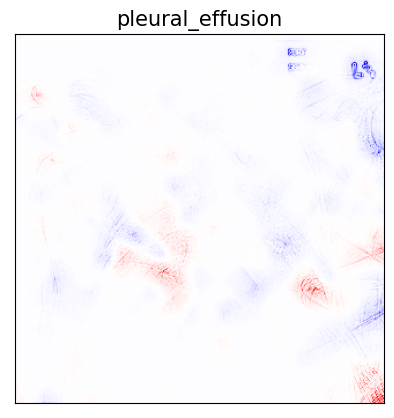

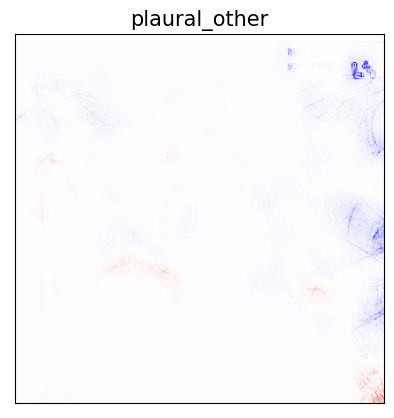

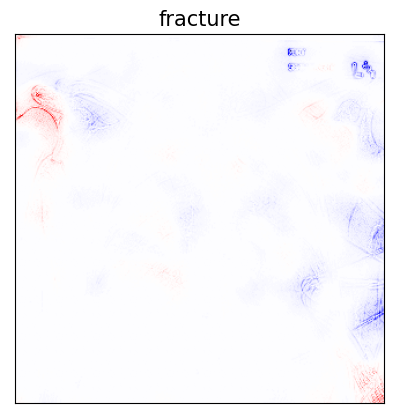

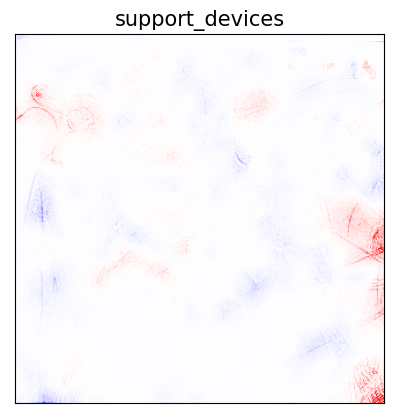

In [12]:
image, concepts = transform(orig_image).to(device), torch.FloatTensor(samples[0][1]).to(device)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")
    
# get saliecy maps for top 5 concepts
pred_precent_concepts = []
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        pred_precent_concepts.append((idx, i.item()))

pred_precent_concepts = sorted(pred_precent_concepts, key=lambda x: -x[1])

for i in range(pred_concepts.size(1)):
    filter_out = torch.zeros_like(pred_concepts)
    filter_out[:,i] += 1

    # Get the gradient of each input
    image_gradient = torch.autograd.grad(
        pred_concepts,
        image,
        grad_outputs=filter_out,
        retain_graph=True)[0]


    attr = heatmap(image_gradient, cmap_name='seismic')

    plt.xticks([])
    plt.yticks([])
    plt.title(label=concept_index_to_string(i), fontsize=15)
    plt.imshow(attr.squeeze(), cmap='seismic')
    #plt.savefig(f'temp/{i}.png')
    plt.show()

    plt.close() 
